# Transformer-layer sweep on TCGA-BRCA

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

The reviewer asked what supports taking embeddings from Transformer layer 4.
This is the one layer sweep that exists: TCGA-BRCA against the other TCGA
cancers (404 samples, 74 BRCA). Every depth gets the same mean-pooled
9,984-dim window embedding and the same classifier: standardised elastic-net
logistic regression, leave-one-out CV, with C and l1_ratio picked by an inner
stratified 3-fold grid search. Only the layer changes.

Each bar is the mean of 1,000 bootstrap resamples of the LOO predictions
(seed 42), and its error bar is the bootstrap SD. Layer 0, the token embedding
before any Transformer block, is computed and printed but not drawn, as in the
original panel. The dashed line sits at 99.9 % of the best layer's AUC. Bars at
or above it are green, and the best layer is vermillion.

Panel:
- `tcga_layer_sweep_auc`: AUC against model layer 1-12. Reproduces
  `pool/notebook_tcga/fig_tcga_layer_sweep_auc.png` from the upstream project.


In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: tcga/data
OUT : tcga/output


In [2]:
# ── Constants, bootstrap and data ─────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

N_BOOT = 1000
SEED = 42
NEAR_BEST = 0.999          # bars within 0.1 % of the best AUC are highlighted
# The upstream panel's own rcParams, so the reproduction matches it.
PANEL_RC = {
    "font.size": 6, "axes.titlesize": 8, "axes.labelsize": 6,
    "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 5,
    "axes.linewidth": 0.25, "xtick.major.width": 0.25,
    "ytick.major.width": 0.25, "lines.linewidth": 0.75,
}


def bootstrap_auc(y_true, y_prob, n_boot=N_BOOT, seed=SEED):
    """Bootstrap AUC: mean, SD and percentile 95 % CI over resamples."""
    rng = np.random.RandomState(seed)
    n = len(y_true)
    aucs = []
    for _ in range(n_boot):
        idx = rng.choice(n, n, replace=True)
        yt, yp = y_true[idx], y_prob[idx]
        if len(np.unique(yt)) < 2:
            continue
        aucs.append(roc_auc_score(yt, yp))
    aucs = np.array(aucs)
    return {"auc": aucs.mean(), "std": aucs.std(),
            "ci_lo": np.percentile(aucs, 2.5), "ci_hi": np.percentile(aucs, 97.5)}


# round_trip: pandas' default float parser is not correctly rounded.
preds = pd.read_csv(DATA / "tcga_brca_layer_sweep_predictions.csv",
                    float_precision="round_trip")
rows = []
for layer, g in preds.groupby("layer"):
    r = bootstrap_auc(g["y_true"].values, g["y_prob"].values)
    rows.append({"layer": layer, "n": len(g), "n_pos": int(g["y_true"].sum()),
                 "auc_point": roc_auc_score(g["y_true"], g["y_prob"]), **r})
df_layer = pd.DataFrame(rows)
print(df_layer.to_string(index=False, float_format="%.4f"))


 layer   n  n_pos  auc_point    auc    std  ci_lo  ci_hi
     0 404     74     0.8198 0.8195 0.0245 0.7729 0.8672
     1 404     74     0.8807 0.8800 0.0222 0.8320 0.9193
     2 404     74     0.8823 0.8816 0.0220 0.8353 0.9207
     3 404     74     0.9035 0.9030 0.0193 0.8615 0.9376
     4 404     74     0.9182 0.9178 0.0158 0.8847 0.9462
     5 404     74     0.9072 0.9070 0.0171 0.8712 0.9373
     6 404     74     0.9052 0.9048 0.0170 0.8702 0.9359
     7 404     74     0.9149 0.9144 0.0163 0.8804 0.9443
     8 404     74     0.8984 0.8979 0.0192 0.8567 0.9331
     9 404     74     0.8998 0.8992 0.0192 0.8582 0.9347
    10 404     74     0.8810 0.8807 0.0213 0.8357 0.9194
    11 404     74     0.8890 0.8887 0.0210 0.8453 0.9254
    12 404     74     0.8636 0.8632 0.0226 0.8174 0.9049


saved: tcga/output/tcga_layer_sweep_auc.pdf
saved: tcga/output/tcga_layer_sweep_auc.png
saved: tcga/output/tcga_layer_sweep_auc.svg
saved: tcga/output/tcga_layer_sweep_auc.tsv


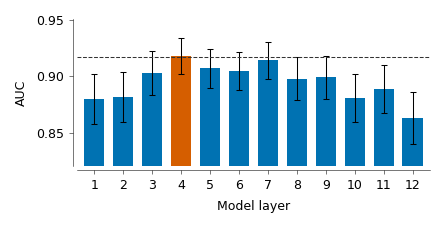

best layer 4 (AUC 0.9178); layer 4 AUC 0.9178 +/- 0.0158, 95% CI [0.8847, 0.9462]; rank of layer 4 among 0-12: 1


In [3]:
# ── Figure: AUC by layer ──────────────────────────────────────────────────────
df_plot = df_layer[df_layer["layer"] != 0].reset_index(drop=True)
best_auc = df_plot["auc"].max()
best_layer = int(df_plot.loc[df_plot["auc"].idxmax(), "layer"])
threshold = best_auc * NEAR_BEST
colors = [OKABE_ITO["vermillion"] if l == best_layer
          else OKABE_ITO["green"] if a >= threshold
          else OKABE_ITO["blue"]
          for l, a in zip(df_plot["layer"], df_plot["auc"])]

with plt.rc_context(PANEL_RC):
    fig, ax = plt.subplots(figsize=(3, 1.5))
    ax.bar(df_plot["layer"], df_plot["auc"], color=colors, width=0.7, linewidth=0)
    ax.errorbar(df_plot["layer"], df_plot["auc"], yerr=df_plot["std"],
                fmt="none", ecolor="black", elinewidth=0.5, capsize=1.5, capthick=0.5)
    ax.axhline(threshold, color="#333333", linestyle="--", linewidth=0.5)

    ax.set_xlabel("Model layer")
    ax.set_ylabel("AUC")
    ax.set_xticks(range(1, 13))
    ax.set_xlim(0.4, 12.6)
    y_min = df_plot["auc"].min() - df_plot["std"].max() - 0.02
    y_max = df_plot["auc"].max() + df_plot["std"].max() + 0.01
    ax.set_ylim(max(0.5, y_min), min(1.0, y_max))

    ax.spines["left"].set_position(("outward", 2))
    ax.spines["bottom"].set_position(("outward", 2))
    ax.tick_params(axis="both", which="both", length=2, pad=2)
    fig.tight_layout()

    source = df_plot.assign(
        color=["best" if c == OKABE_ITO["vermillion"] else
               "near_best" if c == OKABE_ITO["green"] else "other" for c in colors],
        threshold=threshold)
    savefig(fig, OUT, "tcga_layer_sweep_auc", data=source)
    plt.show()

rank = df_layer.sort_values("auc", ascending=False)["layer"].tolist()
l4 = df_layer.set_index("layer").loc[4]
print(f"best layer {best_layer} (AUC {best_auc:.4f}); layer 4 AUC {l4.auc:.4f} "
      f"+/- {l4['std']:.4f}, 95% CI [{l4.ci_lo:.4f}, {l4.ci_hi:.4f}]; "
      f"rank of layer 4 among 0-12: {rank.index(4) + 1}")
